# 02 — Query-adaptive candidate-budget controller (pilot)

**Research idea:** choose how many top-relevance candidates to pass through MMR for each query. The lightweight controller uses only query/candidate features at inference time. Training labels are generated from *training queries only* by selecting the best intent-aware ranking among configurations whose calibrated p95 latency is within a chosen budget.

**Required:** run Notebook 01 first in the same project directory. It writes `artifacts/train_encoded_cpu.pkl`, `artifacts/test_encoded_cpu.pkl`, and `artifacts/run_metadata.json`.

**Critical limitation:** MIMICS has at most ten candidates per query. This notebook verifies the controller/evaluation pipeline, not a publishable large-scale latency claim. A scalable claim requires a realistic larger candidate pool and a separate benchmark. The code keeps the controller interface generic so it can later be evaluated on larger pools.

# 0. Initial Setup

In [2]:
%pip -q install scikit-learn pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


d:\01 Work\13-research-MaxMarginalRelevance\.venv\Scripts\python.exe: No module named pip


In [3]:
! uv pip install seaborn
import seaborn as sns

Using Python 3.13.3 environment at: D:\01 Work\13-research-MaxMarginalRelevance\.venv
Audited 1 package in 6ms


In [4]:
from __future__ import annotations

import json
import pickle
import platform
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import numpy as np
import pandas as pd
import torch
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
sns.set_theme(
    style="darkgrid",
    context="talk",
    font_scale=0.82
)

In [5]:
def find_project_root(start: Path) -> Path:
    """Locate the project package from the current directory or one child level."""
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "rerank_paper" / "core.py").is_file():
            return candidate
        try:
            children = list(candidate.iterdir())
        except (PermissionError, OSError):
            children = []
        for child in children:
            if child.is_dir() and (child / "rerank_paper" / "core.py").is_file():
                return child
    raise FileNotFoundError("Cannot locate rerank_paper/core.py; extract the project ZIP first.")


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from rerank_paper.core import (
    aggregate_metrics,
    benchmark_ranker,
    extract_query_features,
    evaluate_rankings,
    mmr_ranking,
    select_budget_labels,
    set_reproducibility,
)

SEED = 42
set_reproducibility(SEED)
ARTIFACT_DIR = PROJECT_ROOT / "artifacts"
TRAIN_CACHE = ARTIFACT_DIR / "train_encoded_cpu.pkl"
TEST_CACHE = ARTIFACT_DIR / "test_encoded_cpu.pkl"
METADATA_PATH = ARTIFACT_DIR / "run_metadata.json"
if not TRAIN_CACHE.is_file() or not TEST_CACHE.is_file():
    raise FileNotFoundError(
        "Run Notebook 01 first. Expected artifacts/train_encoded_cpu.pkl and test_encoded_cpu.pkl."
    )
with TRAIN_CACHE.open("rb") as f:
    train_encoded_all = pickle.load(f)
with TEST_CACHE.open("rb") as f:
    test_encoded_all = pickle.load(f)
with METADATA_PATH.open("r", encoding="utf-8") as f:
    run_metadata = json.load(f)

DATA_MODE = run_metadata.get("data_mode", "unknown")
ACTION_DEPTHS = (6, 8, 10)
TOP_K = 5
LAMBDA_MULT = 0.65
ALPHA = 0.5
CALIBRATION_QUERY_LIMIT = 80
BENCHMARK_REPEATS = 10





In [6]:
# Candidate-depth actions below 6 cannot return TOP_K=5 robustly across the
# MIMICS subset. Exclude queries with fewer than six candidates from this pilot.
train_encoded_all = {
    qid: item for qid, item in train_encoded_all.items()
    if len(item.record.candidate_ids) >= min(ACTION_DEPTHS)
}
validation_fraction = 0.20
all_train_qids = sorted(train_encoded_all.keys())
if len(all_train_qids) < 10:
    raise ValueError("Need at least ten eligible train queries for a fit/validation split.")
fit_qids, validation_qids = train_test_split(
    all_train_qids, test_size=validation_fraction, random_state=SEED, shuffle=True
)
train_encoded = {qid: train_encoded_all[qid] for qid in fit_qids}
validation_encoded = {qid: train_encoded_all[qid] for qid in validation_qids}
test_encoded = {
    qid: item for qid, item in test_encoded_all.items()
    if len(item.record.candidate_ids) >= min(ACTION_DEPTHS)
}
if len(train_encoded) < 10 or len(validation_encoded) < 3 or len(test_encoded) < 5:
    raise ValueError(
        "Too few eligible queries for the pilot. Check data prep or increase FAST_DEV_RUN limits."
    )

print({
    "data_mode": DATA_MODE,
    "controller_fit_queries": len(train_encoded),
    "validation_queries": len(validation_encoded),
    "final_refit_train_queries": len(train_encoded_all),
    "test_queries_eligible": len(test_encoded),
    "action_depths": ACTION_DEPTHS,
    "top_k": TOP_K,
    "torch_version": torch.__version__,
    "device": next(iter(train_encoded.values())).device.type,
})
if DATA_MODE != "mimics_weak_labels":
    print("WARNING: synthetic data mode. This notebook is only a code smoke test, not research evidence.")

{'data_mode': 'mimics_weak_labels', 'controller_fit_queries': 198, 'validation_queries': 50, 'final_refit_train_queries': 248, 'test_queries_eligible': 119, 'action_depths': (6, 8, 10), 'top_k': 5, 'torch_version': '2.11.0+cu128', 'device': 'cpu'}


# 1. Calibrate fixed candidate-depth actions on training queries

The latency profiles are measured using training-query embeddings only. The budget below is set to the measured p95 latency of the depth-8 action as a reproducible pilot policy. For a paper, report several *predeclared* latency budgets and calibrate them using a training/validation partition on fixed hardware. Very short MIMICS timings may be dominated by timer noise.

In [7]:
calibration_queries = list(train_encoded.values())[: min(CALIBRATION_QUERY_LIMIT, len(train_encoded))]
latency_profiles = {}
for depth in ACTION_DEPTHS:
    def fixed_depth_ranker(item, candidate_depth=depth):
        return mmr_ranking(
            item, lambda_mult=LAMBDA_MULT, top_k=TOP_K,
            candidate_depth=candidate_depth, redundancy_floor=0.0,
        )
    profile = benchmark_ranker(
        calibration_queries, fixed_depth_ranker,
        warmup_calls=3, repeats_per_query=BENCHMARK_REPEATS,
        max_queries=CALIBRATION_QUERY_LIMIT,
    )
    latency_profiles[depth] = profile

latency_calibration_df = pd.DataFrame([
    {"candidate_depth": depth,
     **{key: value for key, value in profile.items() if key != "latencies_ms"}}
    for depth, profile in latency_profiles.items()
]).sort_values("candidate_depth")
BUDGET_MS = float(latency_profiles[8]["p95_ms"])
print(f"Pilot latency budget calibrated to depth-8 train p95: {BUDGET_MS:.6f} ms")
display(latency_calibration_df.round(5))

Pilot latency budget calibrated to depth-8 train p95: 0.607510 ms


,candidate_depth,n_queries,n_calls,device,mean_ms,p50_ms,p95_ms,p99_ms,min_ms,max_ms,calls_per_second_serial
0,6,80,800,cpu,0.39661,0.35020,0.57125,0.67926,0.3382,1.4947,2521.38052
1,8,80,800,cpu,0.43565,0.40365,0.60751,0.78231,0.3394,1.2047,2295.41537
2,10,80,800,cpu,0.40364,0.35730,0.57043,0.66064,0.3400,1.1560,2477.42984


# 2. Build train-only action labels

For each training query, evaluate each budget-feasible candidate depth using the training query's intent judgments, then select the depth with the highest α-nDCG@5 (ties prefer the shallower requested depth). These labels train a small decision tree. Test judgments never affect feature construction, budget selection, or classifier fitting.

In [8]:
latency_p95_by_depth = {
    int(depth): float(profile["p95_ms"])
    for depth, profile in latency_profiles.items()
}
training_labels = select_budget_labels(
    encoded_queries=train_encoded,
    action_depths=ACTION_DEPTHS,
    top_k=TOP_K,
    lambda_mult=LAMBDA_MULT,
    latency_p95_by_depth=latency_p95_by_depth,
    budget_ms=BUDGET_MS,
    alpha=ALPHA,
)
if training_labels.empty:
    raise ValueError("No budget-supervision rows were generated; inspect latency profiles/action depths.")

EXCLUDED_COLUMNS = {"qid", "target_depth", "best_train_alpha_ndcg"}
FEATURE_COLUMNS = [col for col in training_labels.columns if col not in EXCLUDED_COLUMNS]
X_train = training_labels[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=np.float32)
y_train = training_labels["target_depth"].astype(int).to_numpy()

# A shallow tree keeps the controller interpretable and cheap at inference time.
min_leaf = max(3, int(0.02 * len(training_labels)))
controller = DecisionTreeClassifier(
    max_depth=4,
    min_samples_leaf=min_leaf,
    random_state=SEED,
    class_weight=None,
)
controller.fit(X_train, y_train)
print("Training query count:", len(training_labels))
print("Target-depth distribution:")
display(training_labels["target_depth"].value_counts().sort_index().rename("n_queries").to_frame())
print("Controller training accuracy (in-sample diagnostic only):", round(accuracy_score(y_train, controller.predict(X_train)), 4))

Training query count: 198
Target-depth distribution:


,n_queries
target_depth,
6,176
8,20
10,2


Controller training accuracy (in-sample diagnostic only): 0.9141


# 3. Evaluate fixed-depth and adaptive policies on held-out queries

The adaptive ranker extracts the same inexpensive features at test time, predicts a candidate depth, then executes MMR. No relevance judgments are passed to the controller at inference time. Test labels are used only after rankings are produced, for metric calculation.

In [9]:
def build_fixed_depth_ranker(depth: int):
    """Build a stable closure for one fixed MMR candidate depth."""
    def ranker(item):
        return mmr_ranking(
            item, lambda_mult=LAMBDA_MULT, top_k=TOP_K,
            candidate_depth=depth, redundancy_floor=0.0,
        )
    return ranker


def feature_row(item) -> np.ndarray:
    """Create a numeric feature row with the exact order used at fit time."""
    features = extract_query_features(item)
    values = [features[column] for column in FEATURE_COLUMNS]
    return np.nan_to_num(np.asarray(values, dtype=np.float32), nan=0.0, posinf=0.0, neginf=0.0).reshape(1, -1)


def adaptive_budget_ranker(item):
    """Predict depth from inference-time features, then execute MMR at that depth."""
    selected_depth = int(controller.predict(feature_row(item))[0])
    return mmr_ranking(
        item, lambda_mult=LAMBDA_MULT, top_k=TOP_K,
        candidate_depth=selected_depth, redundancy_floor=0.0,
    )

In [10]:
# Internal validation checks generalization within the official train split.
# This set is not used for fitting the controller or calibrating its budget.
validation_rankers = {
    **{f"Fixed MMR depth={depth}": build_fixed_depth_ranker(depth) for depth in ACTION_DEPTHS},
    "Adaptive budget controller (fit split)": adaptive_budget_ranker,
}
validation_per_query_results = evaluate_rankings(
    validation_encoded, rankers=validation_rankers, k_values=(TOP_K,), alpha=ALPHA
)
validation_summary_results = aggregate_metrics(validation_per_query_results)
validation_quality_pivot = validation_summary_results.pivot_table(
    index=["method", "k"], columns="metric", values="mean"
).reset_index()
print("Internal validation metrics (used for development checks, not final paper results)")
display(validation_quality_pivot.round(4))


Internal validation metrics (used for development checks, not final paper results)


metric,method,k,alpha_ndcg,err_ia,intent_coverage,mean_pairwise_cosine,ndcg_any_intent
0,Adaptive budget controller (fit split),5,0.4507,0.1747,0.6593,0.6540,0.4625
1,Fixed MMR depth=10,5,0.4441,0.1748,0.6397,0.6295,0.4541
2,Fixed MMR depth=6,5,0.4507,0.1747,0.6593,0.6540,0.4625
3,Fixed MMR depth=8,5,0.4446,0.1748,0.6397,0.6319,0.4541


In [11]:
# Once the policy/design is frozen using the validation split, refit on the full
# official training split. Recalibrate depth latency using training queries only.
final_calibration_queries = list(train_encoded_all.values())[:min(CALIBRATION_QUERY_LIMIT, len(train_encoded_all))]
final_latency_profiles = {}
for depth in ACTION_DEPTHS:
    def final_fixed_ranker(item, candidate_depth=depth):
        return mmr_ranking(
            item, lambda_mult=LAMBDA_MULT, top_k=TOP_K,
            candidate_depth=candidate_depth, redundancy_floor=0.0,
        )
    final_latency_profiles[depth] = benchmark_ranker(
        final_calibration_queries, final_fixed_ranker,
        warmup_calls=3, repeats_per_query=BENCHMARK_REPEATS,
        max_queries=CALIBRATION_QUERY_LIMIT,
    )
final_latency_p95_by_depth = {
    int(depth): float(profile["p95_ms"])
    for depth, profile in final_latency_profiles.items()
}
BUDGET_MS = float(final_latency_profiles[8]["p95_ms"])
final_training_labels = select_budget_labels(
    encoded_queries=train_encoded_all,
    action_depths=ACTION_DEPTHS,
    top_k=TOP_K,
    lambda_mult=LAMBDA_MULT,
    latency_p95_by_depth=final_latency_p95_by_depth,
    budget_ms=BUDGET_MS,
    alpha=ALPHA,
)
FEATURE_COLUMNS = [
    column for column in final_training_labels.columns
    if column not in {"qid", "target_depth", "best_train_alpha_ndcg"}
]
X_final = final_training_labels[FEATURE_COLUMNS].replace([np.inf, -np.inf], np.nan).fillna(0.0).to_numpy(dtype=np.float32)
y_final = final_training_labels["target_depth"].astype(int).to_numpy()
final_min_leaf = max(3, int(0.02 * len(final_training_labels)))
controller = DecisionTreeClassifier(
    max_depth=4, min_samples_leaf=final_min_leaf, random_state=SEED, class_weight=None
)
controller.fit(X_final, y_final)
latency_profiles = final_latency_profiles
latency_p95_by_depth = final_latency_p95_by_depth
training_labels = final_training_labels
latency_calibration_df = pd.DataFrame([
    {"candidate_depth": depth,
     **{key: value for key, value in profile.items() if key != "latencies_ms"}}
    for depth, profile in final_latency_profiles.items()
]).sort_values("candidate_depth")
print("Final controller refit on full official train split:", len(final_training_labels), "queries")
print("Final train-calibrated budget (ms):", round(BUDGET_MS, 6))


Final controller refit on full official train split: 248 queries
Final train-calibrated budget (ms): 0.546865


In [12]:
test_rankers = {
    **{f"Fixed MMR depth={depth}": build_fixed_depth_ranker(depth) for depth in ACTION_DEPTHS},
    "Adaptive budget controller": adaptive_budget_ranker,
}
per_query_budget_results = evaluate_rankings(
    test_encoded, rankers=test_rankers, k_values=(TOP_K,), alpha=ALPHA
)
summary_budget_results = aggregate_metrics(per_query_budget_results)
quality_pivot = summary_budget_results.pivot_table(
    index=["method", "k"], columns="metric", values="mean"
).reset_index()
print("Final held-out test metrics — controller refit on train only")
display(quality_pivot.round(4))

predicted_depths = {
    qid: int(controller.predict(feature_row(item))[0])
    for qid, item in test_encoded.items()
}
action_distribution = pd.Series(predicted_depths, name="selected_depth").value_counts().sort_index()
display(action_distribution.rename("n_test_queries").to_frame())


Final held-out test metrics — controller refit on train only


metric,method,k,alpha_ndcg,err_ia,intent_coverage,mean_pairwise_cosine,ndcg_any_intent
0,Adaptive budget controller,5,0.4098,0.1568,0.6336,0.6780,0.4044
1,Fixed MMR depth=10,5,0.4146,0.1598,0.6525,0.6498,0.4014
2,Fixed MMR depth=6,5,0.4076,0.1564,0.6294,0.6782,0.4022
3,Fixed MMR depth=8,5,0.4213,0.1606,0.6714,0.6568,0.4087


,n_test_queries
selected_depth,
6,117
8,2


In [13]:
# Measure actual test-query ranking latency. The adaptive measurement includes
# feature extraction + model prediction + MMR, while fixed policies only run MMR.
# Calibration and budget selection used training queries; test timing is reporting only.
timing_queries = list(test_encoded.values())[: min(100, len(test_encoded))]
latency_test_rows = []
for method_name, ranker in test_rankers.items():
    result = benchmark_ranker(
        timing_queries, ranker,
        warmup_calls=3,
        repeats_per_query=BENCHMARK_REPEATS,
        max_queries=100,
    )
    latency_test_rows.append({
        "method": method_name,
        **{key: value for key, value in result.items() if key != "latencies_ms"},
    })
latency_test_results = pd.DataFrame(latency_test_rows).sort_values("p95_ms")
display(latency_test_results.round(5))

fixed_depth_8 = latency_test_results.loc[
    latency_test_results["method"].eq("Fixed MMR depth=8"), "p95_ms"
].iloc[0]
adaptive_p95 = latency_test_results.loc[
    latency_test_results["method"].eq("Adaptive budget controller"), "p95_ms"
].iloc[0]
print(f"Observed adaptive p95 / fixed-depth-8 p95: {adaptive_p95 / fixed_depth_8:.3f}x")
print(f"Training-calibrated budget (ms): {BUDGET_MS:.6f}; observed adaptive p95 (ms): {adaptive_p95:.6f}")

,method,n_queries,n_calls,device,mean_ms,p50_ms,p95_ms,p99_ms,min_ms,max_ms,calls_per_second_serial
1,Fixed MMR depth=8,100,1000,cpu,0.37386,0.34405,0.56330,0.71652,0.3374,0.9726,2674.77373
0,Fixed MMR depth=6,100,1000,cpu,0.39341,0.34880,0.58875,0.72322,0.3387,1.5104,2541.88518
2,Fixed MMR depth=10,100,1000,cpu,0.39547,0.35070,0.59392,0.72232,0.3383,0.8900,2528.61188
3,Adaptive budget controller,100,1000,cpu,0.81792,0.74850,1.12380,1.28820,0.6948,1.5750,1222.61555


Observed adaptive p95 / fixed-depth-8 p95: 1.995x
Training-calibrated budget (ms): 0.546865; observed adaptive p95 (ms): 1.123800


findfont: Failed to find font weight medium for Arial, now using 400.


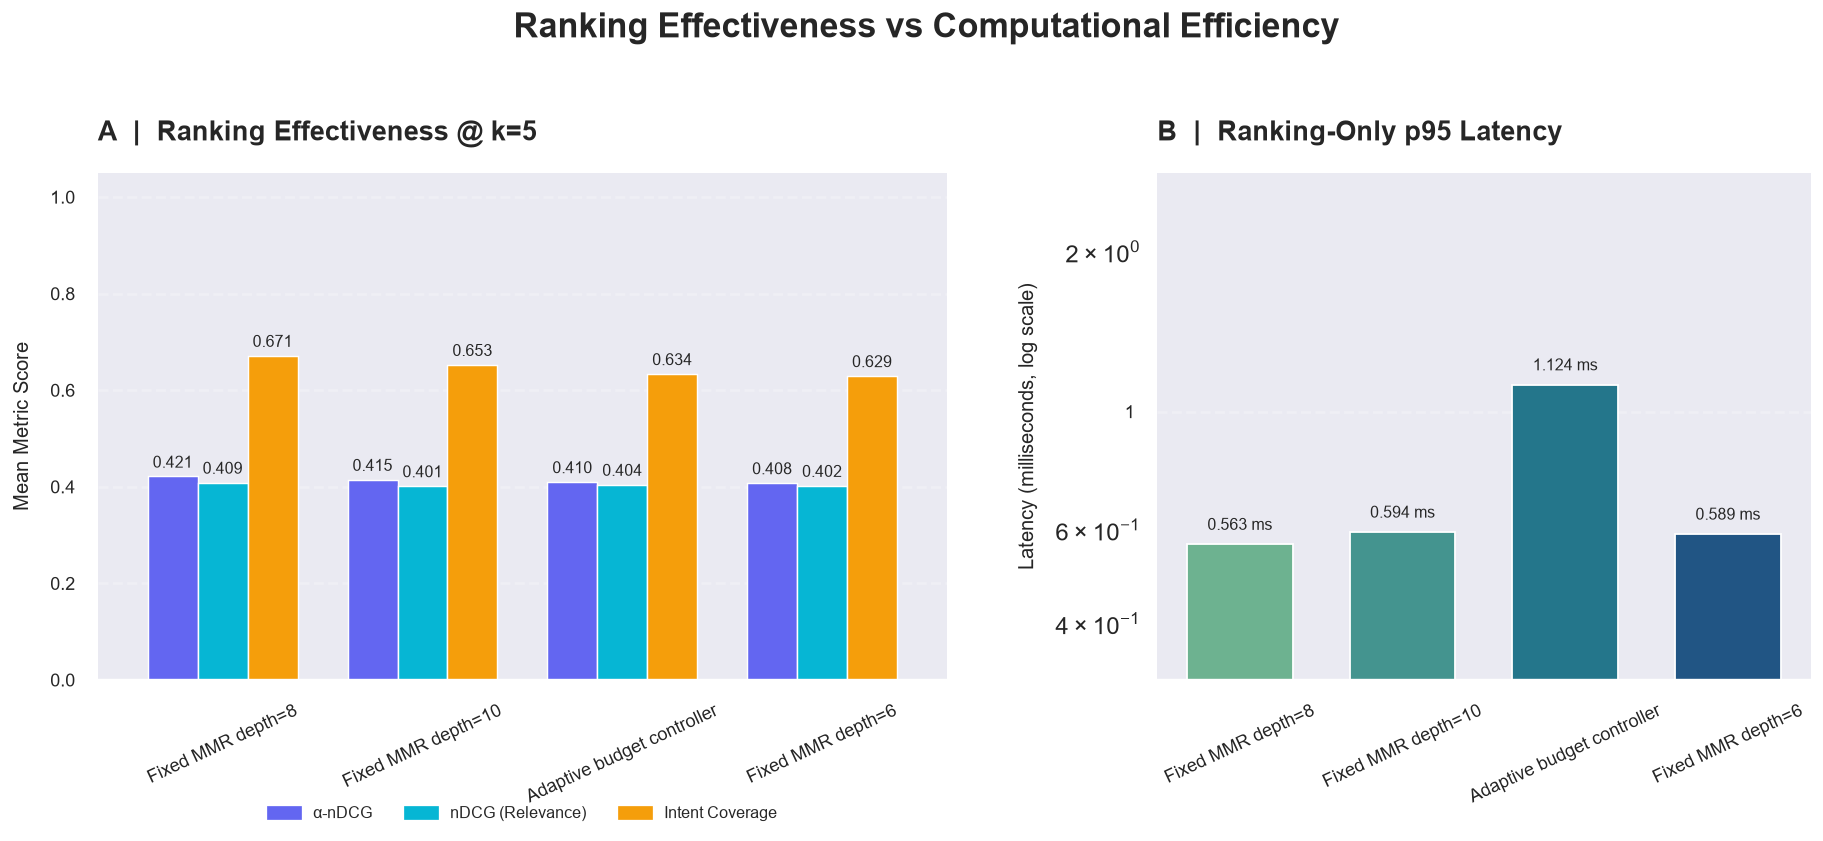

In [ ]:
quality_plot = (
    summary_budget_results[
        summary_budget_results["metric"].isin([
            "alpha_ndcg",
            "ndcg_any_intent",
            "intent_coverage"
        ])
    ]
    .pivot(index="method", columns="metric", values="mean")
)

# Rename metrics
quality_plot = quality_plot.rename(columns={
    "alpha_ndcg": "α-nDCG",
    "ndcg_any_intent": "nDCG (Relevance)",
    "intent_coverage": "Intent Coverage"
})

# Explicit metric ordering
metric_order = [
    "α-nDCG",
    "nDCG (Relevance)",
    "Intent Coverage"
]

quality_plot = quality_plot[metric_order]

# Sort methods by combined ranking quality
quality_plot = quality_plot.sort_values(
    by="α-nDCG",
    ascending=False
)

# Align latency data with ranking methods
latency_plot = (
    latency_test_results
    .set_index("method")["p95_ms"]
    .reindex(quality_plot.index)
)

quality_colors = {
    "α-nDCG": "#6366F1",             # Indigo
    "nDCG (Relevance)": "#06B6D4",   # Cyan
    "Intent Coverage": "#F59E0B"     # Amber
}

# Teal gradient for latency
latency_colors = sns.color_palette(
    "crest",
    n_colors=len(latency_plot)
)

# ============================================================
# 3. CREATE FIGURE
# ============================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 6.5),
    dpi=130,
    gridspec_kw={"width_ratios": [1.3, 1]}
)

fig.suptitle(
    "Ranking Effectiveness vs Computational Efficiency",
    fontsize=19,
    fontweight="bold",
    y=1.04
)

# ============================================================
# 4. LEFT PANEL — RANKING QUALITY
# ============================================================

ax1 = axes[0]

quality_plot.plot(
    kind="bar",
    ax=ax1,
    width=0.75,
    color=[quality_colors[col] for col in quality_plot.columns],
    edgecolor="white",
    linewidth=0.8,
    legend=False
)

# Value annotations
for container in ax1.containers:
    ax1.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9,
        fontweight="medium"
    )

ax1.set_title(
    "A  |  Ranking Effectiveness @ k=5",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=18
)

ax1.set_xlabel("")
ax1.set_ylabel(
    "Mean Metric Score",
    fontsize=11,
    labelpad=10
)

ax1.set_ylim(
    0,
    max(1.05, quality_plot.max().max() * 1.15)
)

ax1.tick_params(
    axis="x",
    rotation=25,
    labelsize=10
)

ax1.tick_params(
    axis="y",
    labelsize=10
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax1.grid(axis="x", visible=False)

ax1.legend(
    handles=[
        plt.Rectangle(
            (0, 0), 1, 1,
            color=quality_colors[col],
            label=col
        )
        for col in metric_order
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=3,
    frameon=False,
    fontsize=9
)

# ============================================================
# 5. RIGHT PANEL — P95 LATENCY
# ============================================================

ax2 = axes[1]

bars = ax2.bar(
    latency_plot.index,
    latency_plot.values,
    width=0.65,
    color=latency_colors,
    edgecolor="white",
    linewidth=1
)

# Log scale
ax2.set_yscale("log")

# Value annotations
for bar, value in zip(bars, latency_plot.values):
    if pd.notna(value) and value > 0:
        ax2.annotate(
            f"{value:.3f} ms",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                value
            ),
            xytext=(0, 6),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="medium"
        )

ax2.set_title(
    "B  |  Ranking-Only p95 Latency",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=18
)

ax2.set_xlabel("")
ax2.set_ylabel(
    "Latency (milliseconds, log scale)",
    fontsize=11,
    labelpad=10
)

ax2.tick_params(
    axis="x",
    rotation=25,
    labelsize=10
)

ax2.tick_params(
    axis="y",
    labelsize=10
)

ax2.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax2.grid(axis="x", visible=False)

# Cleaner log-axis tick formatting
ax2.yaxis.set_major_formatter(
    FuncFormatter(lambda y, _: f"{y:g}")
)

# Add headroom for annotations
valid_latency = latency_plot.dropna()
valid_latency = valid_latency[valid_latency > 0]

if not valid_latency.empty:
    ax2.set_ylim(
        valid_latency.min() / 1.8,
        valid_latency.max() * 2.5
    )

# ============================================================
# 6. FINAL STYLING
# ============================================================

for ax in axes:
    sns.despine(
        ax=ax,
        top=True,
        right=True,
        left=True
    )

    ax.set_axisbelow(True)

plt.subplots_adjust(
    wspace=0.28,
    bottom=0.25,
    top=0.85
)

plt.show()

In [15]:
validation_per_query_results.to_csv(ARTIFACT_DIR / "budget_controller_validation_metrics.csv", index=False)
per_query_budget_results.to_csv(ARTIFACT_DIR / "budget_controller_per_query_metrics.csv", index=False)
summary_budget_results.to_csv(ARTIFACT_DIR / "budget_controller_summary_metrics.csv", index=False)
latency_calibration_df.to_csv(ARTIFACT_DIR / "budget_controller_train_latency.csv", index=False)
latency_test_results.to_csv(ARTIFACT_DIR / "budget_controller_test_latency.csv", index=False)
training_labels.to_csv(ARTIFACT_DIR / "budget_controller_train_labels.csv", index=False)
with (ARTIFACT_DIR / "budget_controller_metadata.json").open("w", encoding="utf-8") as f:
    json.dump({
        "data_mode": DATA_MODE,
        "action_depths": list(ACTION_DEPTHS),
        "top_k": TOP_K,
        "lambda_mult": LAMBDA_MULT,
        "alpha": ALPHA,
        "training_calibrated_budget_ms": BUDGET_MS,
        "feature_columns": FEATURE_COLUMNS,
        "controller": "DecisionTreeClassifier(max_depth=4)",
        "validation_fraction_of_official_train": 0.20,
        "final_controller_fit_queries": len(final_training_labels),
        "warning": "MIMICS max candidate pool is 10; this is a pilot, not evidence of large-scale latency improvements.",
    }, f, indent=2)
print("Saved controller pilot artifacts in", ARTIFACT_DIR)

Saved controller pilot artifacts in D:\01 Work\13-research-MaxMarginalRelevance\artifacts


# 4. Interpret the result correctly

1. Compare the adaptive controller with **all fixed-depth baselines**, not only the baseline it was calibrated against.
2. The controller is allowed to learn from training-query judgments only. Do not use `training_labels` generated from test judgments to fit or tune any model.
3. Its measured latency includes feature extraction and prediction. If controller overhead erases saved MMR time, the approach is not useful in this setting.
4. MIMICS has at most ten documents per query. The experiment tests whether the pipeline is correct; it cannot justify a claim of scalable reranking. Repeat with realistic, larger candidate pools before writing a systems claim.
5. A depth-10 action with fewer than ten available candidates uses all available documents. This keeps the code robust to shorter candidate sets, but per-depth latency should be interpreted alongside candidate counts.